In [1]:

import requests
import pandas as pd

cities = {
    "Hyderabad": (17.3850, 78.4867),
    "Bengaluru": (12.9716, 77.5946),
    "Chennai": (13.0827, 80.2707)
}

all_data = []

for city, (lat, lon) in cities.items():

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2026-10-01",
        "end_date": "2026-10-31",
        "daily": [
            "temperature_2m_mean",
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_sum",
            "relative_humidity_2m_mean",
            "wind_speed_10m_mean",
            "cloud_cover_mean"
        ],
        "timezone": "Asia/Kolkata"
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["daily"])
    df["city"] = city

    all_data.append(df)

# Combine all cities
final_df = pd.concat(all_data, ignore_index=True)

# Save dataset
final_df.to_csv("AtmoSync_Combined_Data.csv", index=False)

print("Dataset downloaded successfully!")
print(final_df.head())
print("Total records:", len(final_df))

# Download the CSV file
from google.colab import files
files.download("AtmoSync_Combined_Data.csv")


Dataset downloaded successfully!
         time  temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
0  2026-10-01                 29.2                33.6                24.6   
1  2026-10-02                 29.1                33.2                25.2   
2  2026-10-03                 28.6                33.0                24.6   
3  2026-10-04                 29.0                33.9                24.8   
4  2026-10-05                 28.8                33.4                24.4   

   precipitation_sum  relative_humidity_2m_mean  wind_speed_10m_mean  \
0                0.0                         52                  6.6   
1                0.0                         49                  7.8   
2                0.2                         53                  6.2   
3                0.0                         52                  6.7   
4                0.0                         48                  6.1   

   cloud_cover_mean       city  
0                59  Hyderabad  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

import pandas as pd

df = pd.read_csv("AtmoSync_Combined_Data.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Shape: (93, 9)

First 5 Rows:
         time  temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
0  2026-10-01                 29.2                33.6                24.6   
1  2026-10-02                 29.1                33.2                25.2   
2  2026-10-03                 28.6                33.0                24.6   
3  2026-10-04                 29.0                33.9                24.8   
4  2026-10-05                 28.8                33.4                24.4   

   precipitation_sum  relative_humidity_2m_mean  wind_speed_10m_mean  \
0                0.0                         52                  6.6   
1                0.0                         49                  7.8   
2                0.2                         53                  6.2   
3                0.0                         52                  6.7   
4                0.0                         48                  6.1   

   cloud_cover_mean       city  
0                59  Hydera

In [3]:

# STEP 2: DATA CLEANING

# Create a copy of original dataset
clean_df = df.copy()

# Convert date into datetime format
clean_df["time"] = pd.to_datetime(clean_df["time"])

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Check missing values
print("Missing Values:")
print(clean_df.isnull().sum())

# Check data types
print("\nData Types:")
print(clean_df.dtypes)

# Sort records by city and date
clean_df = clean_df.sort_values(
    by=["city", "time"]
)

# Save cleaned dataset
clean_df.to_csv(
    "AtmoSync_Cleaned_Data.csv",
    index=False
)

print("\nData Cleaning Completed Successfully!")

print("Final Dataset Shape:", clean_df.shape)


Missing Values:
time                         0
temperature_2m_mean          0
temperature_2m_max           0
temperature_2m_min           0
precipitation_sum            0
relative_humidity_2m_mean    0
wind_speed_10m_mean          0
cloud_cover_mean             0
city                         0
dtype: int64

Data Types:
time                         datetime64[ns]
temperature_2m_mean                 float64
temperature_2m_max                  float64
temperature_2m_min                  float64
precipitation_sum                   float64
relative_humidity_2m_mean             int64
wind_speed_10m_mean                 float64
cloud_cover_mean                      int64
city                                 object
dtype: object

Data Cleaning Completed Successfully!
Final Dataset Shape: (93, 9)


In [4]:
city_analysis = clean_df.groupby("city").agg({
    "temperature_2m_mean": "mean",
    "temperature_2m_max": "max",
    "temperature_2m_min": "min",
    "relative_humidity_2m_mean": "mean",
    "precipitation_sum": "sum",
    "wind_speed_10m_mean": "mean"
})

print("CITY-WISE WEATHER ANALYSIS")
print(city_analysis.round(2))

city_analysis.to_csv("AtmoSync_City_Analysis.csv")

CITY-WISE WEATHER ANALYSIS
           temperature_2m_mean  temperature_2m_max  temperature_2m_min  \
city                                                                     
Bengaluru                23.89                31.0                17.4   
Chennai                  28.89                35.4                24.2   
Hyderabad                27.95                33.9                21.2   

           relative_humidity_2m_mean  precipitation_sum  wind_speed_10m_mean  
city                                                                          
Bengaluru                      71.81               93.6                 8.35  
Chennai                        74.81              264.8                 8.62  
Hyderabad                      52.87               19.1                 7.82  


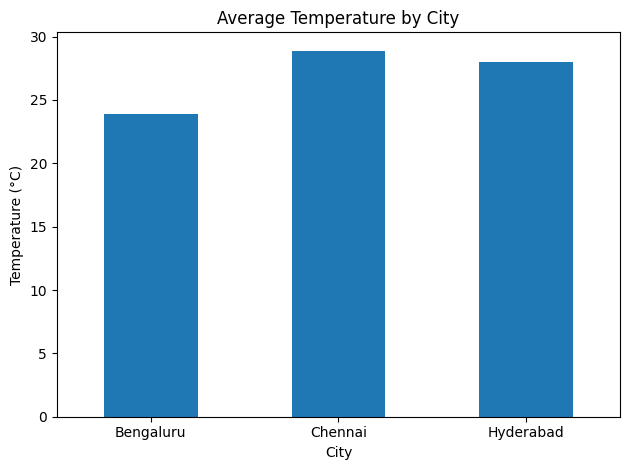

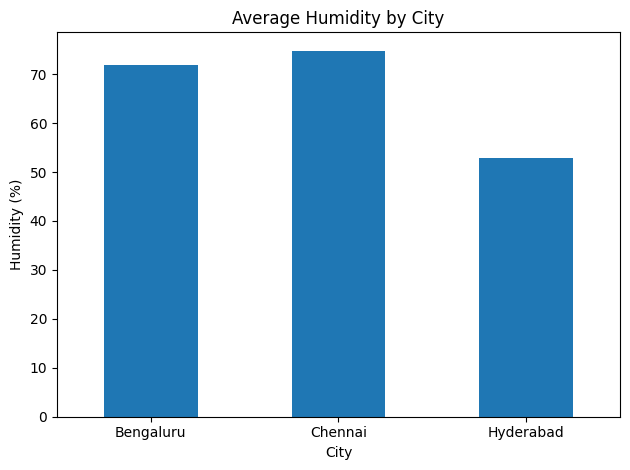

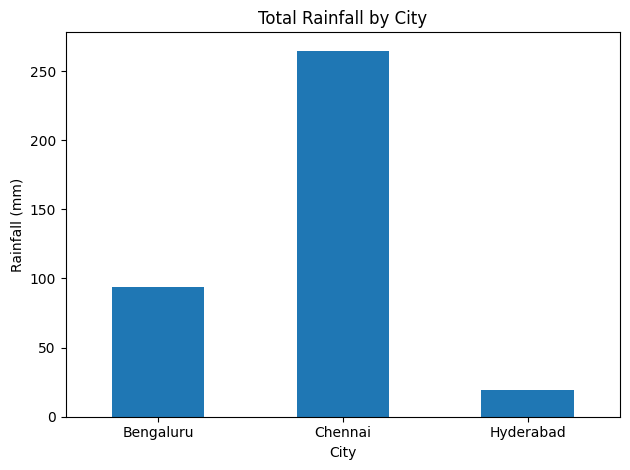

All comparison graphs created successfully!


In [5]:
import matplotlib.pyplot as plt

# 1. Average Temperature Comparison
city_analysis["temperature_2m_mean"].plot(
    kind="bar", title="Average Temperature by City",
    ylabel="Temperature (°C)", xlabel="City"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("AtmoSync_Temperature_Comparison.png")
plt.show()

# 2. Average Humidity Comparison
city_analysis["relative_humidity_2m_mean"].plot(
    kind="bar", title="Average Humidity by City",
    ylabel="Humidity (%)", xlabel="City"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("AtmoSync_Humidity_Comparison.png")
plt.show()

# 3. Total Rainfall Comparison
city_analysis["precipitation_sum"].plot(
    kind="bar", title="Total Rainfall by City",
    ylabel="Rainfall (mm)", xlabel="City"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("AtmoSync_Rainfall_Comparison.png")
plt.show()

print("All comparison graphs created successfully!")

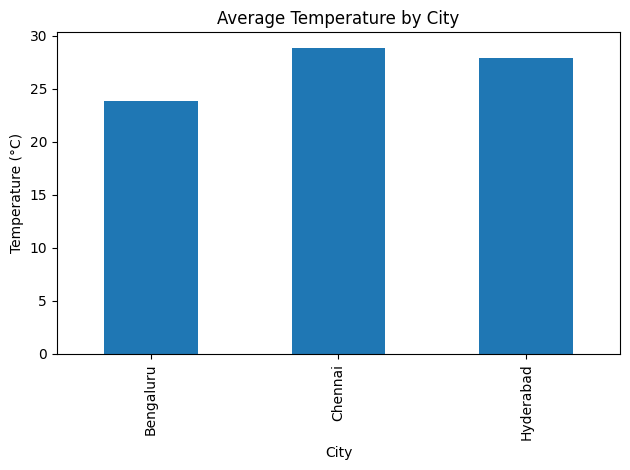

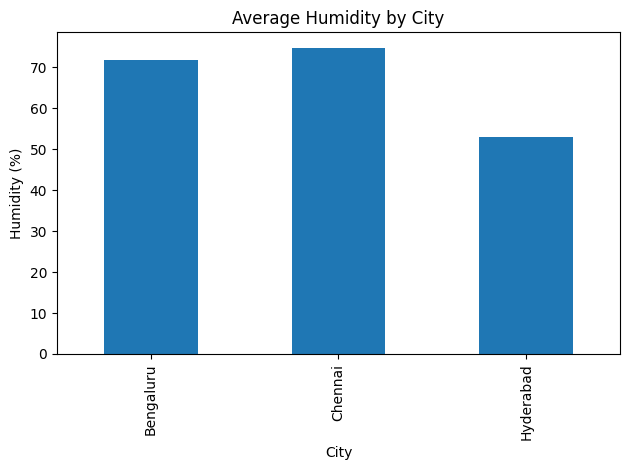

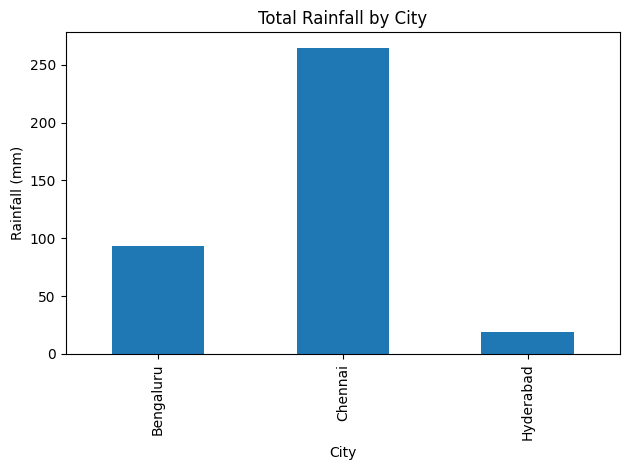

All project files saved successfully!


In [6]:
import matplotlib.pyplot as plt

# 1. Average temperature comparison
clean_df.groupby("city")["temperature_2m_mean"].mean().plot(
    kind="bar", title="Average Temperature by City",
    ylabel="Temperature (°C)", xlabel="City"
)
plt.tight_layout()
plt.savefig("Temperature_Comparison.png")
plt.show()

# 2. Average humidity comparison
clean_df.groupby("city")["relative_humidity_2m_mean"].mean().plot(
    kind="bar", title="Average Humidity by City",
    ylabel="Humidity (%)", xlabel="City"
)
plt.tight_layout()
plt.savefig("Humidity_Comparison.png")
plt.show()

# 3. Total rainfall comparison
clean_df.groupby("city")["precipitation_sum"].sum().plot(
    kind="bar", title="Total Rainfall by City",
    ylabel="Rainfall (mm)", xlabel="City"
)
plt.tight_layout()
plt.savefig("Rainfall_Comparison.png")
plt.show()

# Save datasets
clean_df.to_csv("AtmoSync_Cleaned_Data.csv", index=False)
city_analysis.to_csv("AtmoSync_City_Analysis.csv")

print("All project files saved successfully!")

In [7]:
import os

files = [
    "Temperature_Comparison.png",
    "Humidity_Comparison.png",
    "Rainfall_Comparison.png"
]

for file in files:
    if os.path.exists(file):
        print("✅ Saved:", file)
    else:
        print("❌ Not found:", file)

✅ Saved: Temperature_Comparison.png
✅ Saved: Humidity_Comparison.png
✅ Saved: Rainfall_Comparison.png
